In [1]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [2]:
train = pd.read_csv("../data/processed/train_processed.csv")
test = pd.read_csv("../data/processed/test_processed.csv")

X_train = train.drop("is_fraud", axis=1)
y_train = train["is_fraud"]

X_test = test.drop("is_fraud", axis=1)
y_test = test["is_fraud"]

In [3]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=15,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        max_depth=3,
        random_state=42
    )
}

In [4]:
results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

In [5]:
results_df = pd.DataFrame(results)
results_df

,Model,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.071627,0.719814,0.130290,0.871391
1,Decision Tree,0.161581,0.812121,0.269534,0.902380
2,Random Forest,0.625438,0.832168,0.714143,0.995639
3,Gradient Boosting,0.810706,0.684848,0.742482,0.978498


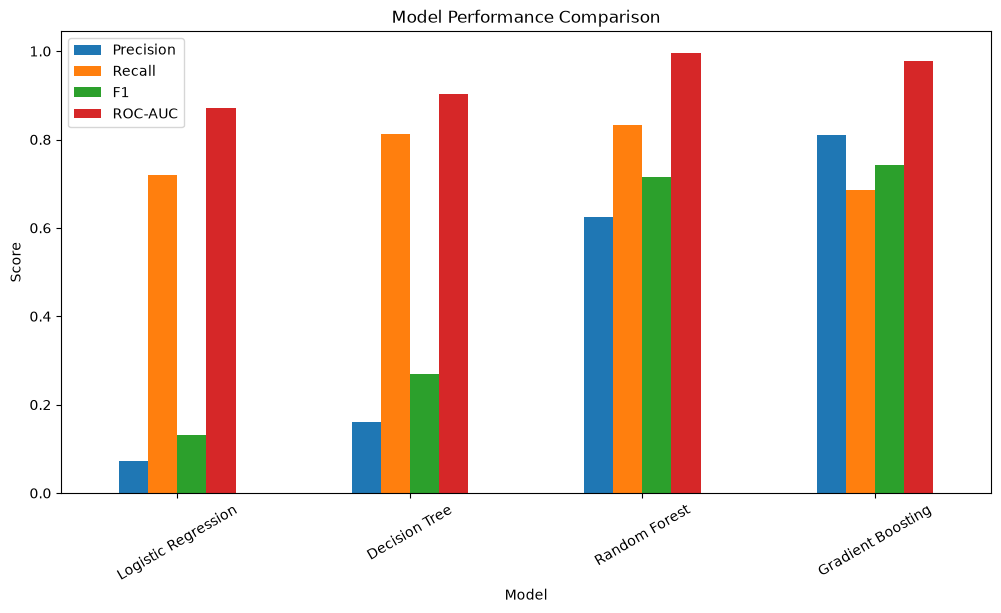

In [6]:
results_df.set_index("Model")[["Precision", "Recall", "F1", "ROC-AUC"]].plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.show()

In [7]:
best_model_name = results_df.sort_values(
    "F1",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_model_name]

print("Selected model:", best_model_name)

Selected model: Gradient Boosting


In [8]:
predictions = best_model.predict(X_test)

print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    553574
           1       0.81      0.68      0.74      2145

    accuracy                           1.00    555719
   macro avg       0.90      0.84      0.87    555719
weighted avg       1.00      1.00      1.00    555719



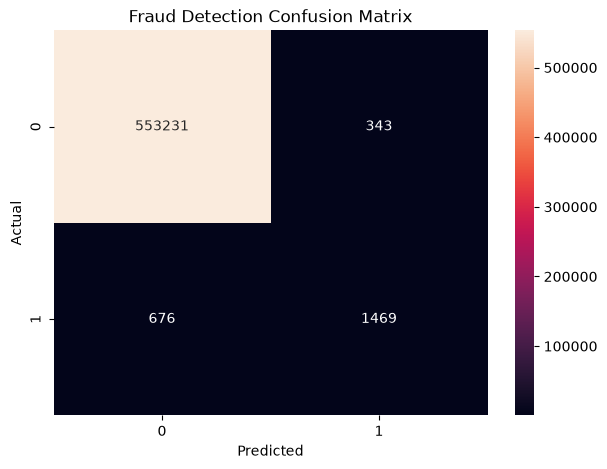

In [9]:
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fraud Detection Confusion Matrix")
plt.show()

In [10]:
joblib.dump(best_model, "../models/fraud_model.pkl")

['../models/fraud_model.pkl']

In [11]:
results_df.to_csv("../reports/model_comparison.csv", index=False)

In [12]:
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    max_iter=100,
    random_state=42
)

mlp.fit(X_train, y_train)

mlp_predictions = mlp.predict(X_test)

print(classification_report(y_test, mlp_predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    553574
           1       0.87      0.74      0.80      2145

    accuracy                           1.00    555719
   macro avg       0.94      0.87      0.90    555719
weighted avg       1.00      1.00      1.00    555719

